In [1]:
import os
import subprocess

DATA_DIR = "data"
if not os.path.exists(DATA_DIR):
    os.mkdir(DATA_DIR)


for month in range(1, 13):
    if not os.path.exists(f"{DATA_DIR}/{month}.parquet"):
        subprocess.run(
            [
                "wget",
                f"https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-{month:02}.parquet",
                "-O",
                f"{DATA_DIR}/{month}.parquet",
            ]
        )


total_size = sum(
    os.path.getsize(f"{DATA_DIR}/{month}.parquet") for month in range(1, 13)
)  # bytes
total_size_mb = total_size // (1024 * 1024)
print(f"Total dataset size: {total_size_mb} MB")

Total dataset size: 660 MB


In [2]:
if not os.path.exists(f"{DATA_DIR}/taxi_zone_lookup.csv"):
    subprocess.run(
        [
            "wget",
            "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv",
            "-O",
            f"{DATA_DIR}/taxi_zone_lookup.csv",
        ]
    )

### 1. Data reading
- load all 2024 months of taxi rides
- also load taxi zone lookup data
- include only rides starting in 2024 and ending at most at 01.01.2025
- optimize data types, particularly for integers and categorical strings

In [3]:
import polars as pl


dfs = []
for month in range(1, 13):
    lf = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    lf = lf.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
        pl.col("VendorID", "RatecodeID", "payment_type", "passenger_count").cast(
            pl.UInt8
        ),
        pl.col("PULocationID", "DOLocationID").cast(pl.UInt16),
        pl.col("store_and_fwd_flag").cast(pl.Categorical),
    )
    dfs.append(lf)

lf_2024 = pl.concat(dfs)
print(lf_2024.explain())

UNION[maintain_order: true]
  PLAN 0:
     WITH_COLUMNS:
     [col("tpep_pickup_datetime").dt.cast_time_unit(), col("tpep_dropoff_datetime").dt.cast_time_unit(), col("VendorID").strict_cast(UInt8), col("RatecodeID").strict_cast(UInt8), col("payment_type").strict_cast(UInt8), col("passenger_count").strict_cast(UInt8), col("PULocationID").strict_cast(UInt16), col("DOLocationID").strict_cast(UInt16), col("store_and_fwd_flag").strict_cast(Categorical)] 
      Parquet SCAN [data/1.parquet]
      PROJECT */19 COLUMNS
      ESTIMATED ROWS: 2964624
  PLAN 1:
     WITH_COLUMNS:
     [col("tpep_pickup_datetime").dt.cast_time_unit(), col("tpep_dropoff_datetime").dt.cast_time_unit(), col("VendorID").strict_cast(UInt8), col("RatecodeID").strict_cast(UInt8), col("payment_type").strict_cast(UInt8), col("passenger_count").strict_cast(UInt8), col("PULocationID").strict_cast(UInt16), col("DOLocationID").strict_cast(UInt16), col("store_and_fwd_flag").strict_cast(Categorical)] 
      Parquet SCAN [data/2.

In [4]:
from datetime import datetime

lf_2024 = lf_2024.filter(
    pl.col("tpep_pickup_datetime") >= datetime(2024, 1, 1),
    pl.col("tpep_pickup_datetime") < datetime(2025, 1, 1),
    pl.col("tpep_dropoff_datetime") < datetime(2025, 1, 1),
)

In [5]:
zones = pl.read_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")

In [6]:
zones.describe()

statistic,LocationID,Borough,Zone,service_zone
str,f64,str,str,str
"""count""",265.0,"""265""","""265""","""265"""
"""null_count""",0.0,"""0""","""0""","""0"""
"""mean""",133.0,null,null,null
"""std""",76.643112,null,null,null
"""min""",1.0,"""Bronx""","""Allerton/Pelham Gardens""","""Airports"""
"""25%""",67.0,null,null,null
"""50%""",133.0,null,null,null
"""75%""",199.0,null,null,null
"""max""",265.0,"""Unknown""","""Yorkville West""","""Yellow Zone"""


### 2. Data cleaning and filtering
- fill NULL values in passengers_count with 1
- remove rides with zero passengers
- if a ride has over 6 passengers, replace the value with 6
- remove rides lasting over 2 hours
- in all money-related columns, replace values with absolute value to fix - - negative amounts
- remove rides with over 1000 dollars in any money-related column
- remove rows with values of RatecodeID or VendorID missing or outside those - defined in the data dictionary

In [7]:
money_cols = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

lf_2024 = (
    lf_2024.with_columns(pl.col("passenger_count").fill_null(1))
    .filter(pl.col("passenger_count") > 0)
    .with_columns(pl.col("passenger_count").clip(upper_bound=6))
    .filter(
        (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime"))
        <= pl.duration(hours=2)
    )
    .with_columns(pl.col(money_cols).abs())
    .filter(pl.max_horizontal(pl.col(money_cols)) <= 1000)
    .filter(
        pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
        pl.col("VendorID").is_in([1, 2, 6, 7]),
    )
)

3. Data transformation
- combine payment type values for "No charge", "Dispute", "Unknown" and - - - "Voided trip" into one type, so we have only credit card, cash, or other
- replace PULocationID and DOLocationID with borough names by joining taxi - - zone lookup and removing unnecessary columns
- add boolean variable is_airport_ride, true if there is non-zero airport fee
- add boolean variable is_rush_hour, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

0 = Flex Fare trip 1 = Credit card 2 = Cash 3 = No charge 4 = Dispute 5 = Unknown 6 = Voided trip

In [8]:
zones_lf = zones.lazy().select(
    pl.col("LocationID").cast(pl.UInt16), pl.col("Borough").cast(pl.Categorical)
)

time_of_day = pl.col("tpep_pickup_datetime").dt.time()

lf_2024 = (
    lf_2024.with_columns(
        pl.when(pl.col("payment_type") == 1)
        .then(pl.lit("credit_card"))
        .when(pl.col("payment_type") == 2)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .cast(pl.Categorical)
        .alias("payment_type")
    )
    .join(
        zones_lf.rename({"LocationID": "PULocationID", "Borough": "pu_borough"}),
        on="PULocationID",
        how="left",
    )
    .join(
        zones_lf.rename({"LocationID": "DOLocationID", "Borough": "do_borough"}),
        on="DOLocationID",
        how="left",
    )
    .drop("PULocationID", "DOLocationID")
    .with_columns(
        is_airport_ride=pl.col("Airport_fee") > 0,
        is_rush_hour=(pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
        & (
            time_of_day.is_between(pl.time(6, 30), pl.time(9, 30), closed="left")
            | time_of_day.is_between(pl.time(15, 30), pl.time(20, 0), closed="left")
        ),
    )
)

4. Feature extraction
- apply dummy encoding to features:
    - payment type
    - pickup borough
    - dropoff borough


In [9]:
print(zones.select("Borough").unique())

shape: (8, 1)
┌───────────────┐
│ Borough       │
│ ---           │
│ str           │
╞═══════════════╡
│ EWR           │
│ Staten Island │
│ Brooklyn      │
│ Unknown       │
│ Bronx         │
│ Manhattan     │
│ Queens        │
│ N/A           │
└───────────────┘


In [10]:
payment_types = ["credit_card", "cash", "other"]
boroughs = zones["Borough"].unique().sort().to_list()


def slug(s: str):
    return s.lower().replace(" ", "_").replace("/", "_")


dummy_expression = (
    [
        (pl.col("payment_type") == p).cast(pl.UInt8).alias(f"payment_{p}")
        for p in payment_types
    ]
    + [
        (pl.col("pu_borough") == b).cast(pl.UInt8).alias(f"pu_{slug(b)}")
        for b in boroughs
    ]
    + [
        (pl.col("do_borough") == b).cast(pl.UInt8).alias(f"do_{slug(b)}")
        for b in boroughs
    ]
)

lf_2024 = lf_2024.with_columns(dummy_expression)

In [11]:
print(lf_2024.collect_schema().names())

['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'pu_borough', 'do_borough', 'is_airport_ride', 'is_rush_hour', 'payment_credit_card', 'payment_cash', 'payment_other', 'pu_bronx', 'pu_brooklyn', 'pu_ewr', 'pu_manhattan', 'pu_n_a', 'pu_queens', 'pu_staten_island', 'pu_unknown', 'do_bronx', 'do_brooklyn', 'do_ewr', 'do_manhattan', 'do_n_a', 'do_queens', 'do_staten_island', 'do_unknown']


- add integer variables for counting daily events:
    - total number of rides (target variable)
    - number of airport rides
    - number of rush hour rides


In [12]:
counts_exprs = [
    pl.len().alias("n_rides"),
    pl.col("is_airport_ride").sum().alias("n_airport_rides"),
    pl.col("is_rush_hour").sum().alias("n_rush_hour_rides"),
]

- add features aggregating daily rides information:
    - average fare amount
    - median distance
    - sum of total amounts
    - total amount paid by card, cash, and other
    - total congestion surcharge
    - total number of passengers


In [13]:
aggregate_exprs = [
    pl.col("fare_amount").mean().alias("avg_fare_amount"),
    pl.col("trip_distance").median().alias("median_distance"),
    pl.col("total_amount").sum().alias("sum_total_amount"),
    pl.col("total_amount")
    .filter(pl.col("payment_type") == "credit_card")
    .sum()
    .alias("total_amount_card"),
    pl.col("total_amount")
    .filter(pl.col("payment_type") == "cash")
    .sum()
    .alias("total_amount_cash"),
    pl.col("total_amount")
    .filter(pl.col("payment_type") == "other")
    .sum()
    .alias("total_amount_other"),
    pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
    pl.col("passenger_count").sum().alias("total_passengers"),
]

- add time features:
    - quarter
    - month
    - day_of_month
    - day_of_week
    - is_weekend (boolean)
- add column date, indicating day with given features
- make sure to exclude other columns, unnecessary for machine learning, e.g. - IDs, timestamps, unused financial information
- properly name all columns
- save results as dataset.parquet file

In [14]:
dummy_cols = [
    e.meta.output_name() for e in dummy_expression
]  # names of the dummy columns


daily = (
    lf_2024.with_columns(date=pl.col("tpep_pickup_datetime").dt.date())
    .group_by("date")
    .agg(
        *counts_exprs,
        *aggregate_exprs,
        pl.col(dummy_cols).sum(),
    )
)

In [15]:
daily = daily.with_columns(
    quarter=pl.col("date").dt.quarter(),
    month=pl.col("date").dt.month(),
    day_of_month=pl.col("date").dt.day(),
    day_of_week=pl.col("date").dt.weekday(),
    is_weekend=pl.col("date").dt.weekday() > 5,
).sort("date")

In [16]:
dataset = daily.collect()
dataset.write_parquet("dataset.parquet")

## 5. Data analysis
- print shape
- show top rows
- describe statistics
- print schema
- plot target variable (daily number of rides):
    - histogram of values
    - line plot, date vs number of rides (remember to sort by date)

(366, 36)


date,n_rides,n_airport_rides,n_rush_hour_rides,avg_fare_amount,median_distance,sum_total_amount,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_credit_card,payment_cash,payment_other,pu_bronx,pu_brooklyn,pu_ewr,pu_manhattan,pu_n_a,pu_queens,pu_staten_island,pu_unknown,do_bronx,do_brooklyn,do_ewr,do_manhattan,do_n_a,do_queens,do_staten_island,do_unknown,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i8,i8,i8,i8,bool
2024-01-01,69665,8352,19397,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,52970,14491,2204,82,664,21,59261,93,9270,3,271,583,3825,388,58606,605,5183,31,444,1,1,1,1,false
2024-01-02,72583,9828,31009,21.501448,1.82,2.2501e6,1.8023e6,396334.47,51441.03,160615.0,104071,55174,15387,2022,167,684,20,60493,54,10897,2,266,555,3411,319,62613,437,4831,32,385,1,1,2,2,false
2024-01-03,79566,9140,33386,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,61343,16202,2021,228,679,16,68074,36,10217,1,315,640,3464,282,69706,398,4589,14,473,1,1,3,3,false
2024-01-04,99077,8270,43569,18.866102,1.75,2760359.9,2.2559e6,444631.77,59823.2,226627.5,135815,78738,17994,2345,244,666,10,88459,40,9272,1,385,757,3463,226,89107,346,4615,14,549,1,1,4,4,false
2024-01-05,98860,7460,40516,18.246814,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137166,78701,17699,2460,183,606,8,89232,37,8399,1,394,651,3182,222,89459,345,4373,20,608,1,1,5,5,false


statistic,date,n_rides,n_airport_rides,n_rush_hour_rides,avg_fare_amount,median_distance,sum_total_amount,total_amount_card,total_amount_cash,total_amount_other,total_congestion_surcharge,total_passengers,payment_credit_card,payment_cash,payment_other,pu_bronx,pu_brooklyn,pu_ewr,pu_manhattan,pu_n_a,pu_queens,pu_staten_island,pu_unknown,do_bronx,do_brooklyn,do_ewr,do_manhattan,do_n_a,do_queens,do_staten_island,do_unknown,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100096.278689,8977.852459,29939.912568,19.952296,1.718634,2.9111e6,2.4607e6,372228.863825,78155.394973,230203.74459,134959.762295,82240.893443,14923.442623,2931.942623,206.071038,882.128415,15.983607,88509.994536,60.18306,10106.713115,2.579235,312.625683,590.032787,4008.661202,284.52459,89042.221311,484.617486,5212.079235,25.251366,448.89071,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15372.291655,1716.382261,19692.67237,1.204554,0.10091,461500.084055,428830.86428,36188.898027,17265.430834,37864.67368,18725.125285,14161.113031,1357.230224,554.311622,51.127939,201.839764,7.71263,15154.428195,18.122773,1764.946704,1.735371,57.290409,67.941264,581.872824,73.624208,14677.843644,93.74735,689.263364,6.752549,92.05141,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47390.0,3355.0,0.0,16.676264,1.5,1.3260e6,996577.34,240633.43,41303.84,107825.0,74198.0,34052.0,10244.0,1656.0,48.0,298.0,2.0,41757.0,23.0,4935.0,0.0,149.0,370.0,1831.0,122.0,41657.0,261.0,2826.0,9.0,192.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89572.0,7869.0,0.0,19.125929,1.66,2.5818e6,2.1701e6,352429.45,65781.9,203501.0,122219.0,72543.0,14109.0,2566.0,166.0,731.0,10.0,77349.0,46.0,8862.0,1.0,273.0,544.0,3682.0,236.0,78535.0,418.0,4773.0,20.0,390.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100781.0,9018.0,39515.0,19.950719,1.7,2.9164e6,2.4629e6,375884.77,79217.11,232817.5,134078.0,83419.0,14966.0,2910.0,216.0,938.0,15.0,89891.0,59.0,10072.0,2.0,310.0,591.0,4009.0,275.0,90291.0,481.0,5251.0,25.0,444.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110799.0,10144.0,44779.0,20.713722,1.77,3.2228e6,2.7450e6,398461.95,90279.69,256939.5,147187.0,91738.0,15833.0,3271.0,243.0,1019.0,20.0,99601.0,70.0,11253.0,3.0,347.0,639.0,4378.0,335.0,99446.0,549.0,5703.0,30.0,515.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141677.0,14903.0,56566.0,24.447593,2.2,4.4621e6,3.9163e6,449948.51,123894.72,330475.0,199440.0,120976.0,17994.0,4596.0,323.0,1673.0,47.0,128160.0,125.0,16176.0,8.0,505.0,801.0,6236.0,583.0,127687.0,716.0,6851.0,51.0,718.0,4.0,12.0,31.0,7.0,1.0


Schema({'date': Date, 'n_rides': UInt32, 'n_airport_rides': UInt32, 'n_rush_hour_rides': UInt32, 'avg_fare_amount': Float64, 'median_distance': Float64, 'sum_total_amount': Float64, 'total_amount_card': Float64, 'total_amount_cash': Float64, 'total_amount_other': Float64, 'total_congestion_surcharge': Float64, 'total_passengers': Int64, 'payment_credit_card': Int64, 'payment_cash': Int64, 'payment_other': Int64, 'pu_bronx': Int64, 'pu_brooklyn': Int64, 'pu_ewr': Int64, 'pu_manhattan': Int64, 'pu_n_a': Int64, 'pu_queens': Int64, 'pu_staten_island': Int64, 'pu_unknown': Int64, 'do_bronx': Int64, 'do_brooklyn': Int64, 'do_ewr': Int64, 'do_manhattan': Int64, 'do_n_a': Int64, 'do_queens': Int64, 'do_staten_island': Int64, 'do_unknown': Int64, 'quarter': Int8, 'month': Int8, 'day_of_month': Int8, 'day_of_week': Int8, 'is_weekend': Boolean})


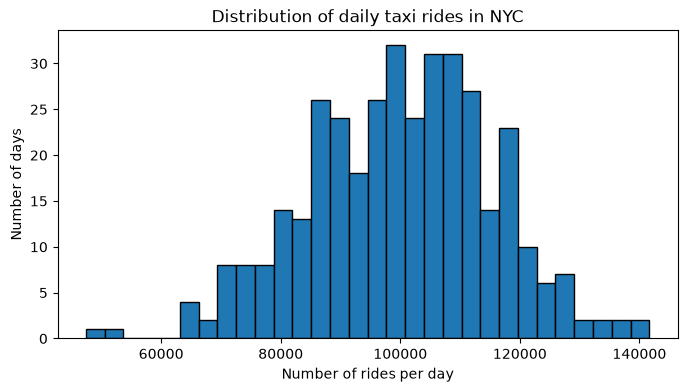

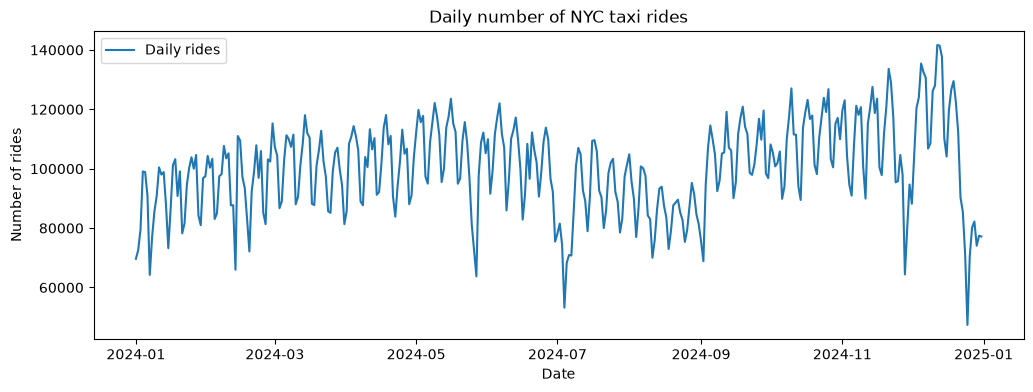

In [17]:
import matplotlib.pyplot as plt

print(dataset.shape)
display(dataset.head())
display(dataset.describe())
print(dataset.schema)

pdf = dataset.sort("date").to_pandas()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pdf["n_rides"], bins=30, edgecolor="black")
ax.set_title("Distribution of daily taxi rides in NYC")
ax.set_xlabel("Number of rides per day")
ax.set_ylabel("Number of days")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pdf["date"], pdf["n_rides"], label="Daily rides")
ax.set_title("Daily number of NYC taxi rides")
ax.set_xlabel("Date")
ax.set_ylabel("Number of rides")
ax.legend()
plt.show()